In [19]:
import pandas as pd
import os
parent_dir = '/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/metrics_eval_layers_pooled_cosmx_X/'
metric_dirs = os.listdir(parent_dir)
sep_files = sorted([os.path.join(parent_dir,x,'cell_type_separation_metrics_layers_pooled.csv') for x in metric_dirs if os.path.exists(os.path.join(parent_dir,x,'cell_type_separation_metrics_layers_pooled.csv'))])
sep_df = pd.concat([pd.read_csv(f) for f in sep_files])
# sep_df = pd.read_csv('/work/magroup/skrieger/Syndri/data/xenium_noise_experiment/metrics_eval_layers_pooled/B10_B10/cell_type_separation_metrics_worstadj.csv')
# sep_df['tissue'].iloc[0]
sep_df['dropout']= sep_df['tissue'].apply(lambda x: x.split('_')[-1])

sep_df['input_layer'].unique()

array(['X'], dtype=object)

In [20]:
sep_df[~sep_df['calinski_harabasz'].isna()]
sep_df['tissue'].value_counts()

tissue
cosmx_nsclc_Lung12_adata_annotated_dropout_1pct        12
cosmx_nsclc_Lung13_adata_annotated_dropout_1pct        12
cosmx_nsclc_Lung5-Rep1_adata_annotated_dropout_1pct    12
cosmx_nsclc_Lung5-Rep3_adata_annotated_dropout_1pct    12
cosmx_nsclc_Lung6_adata_annotated_dropout_1pct         12
cosmx_nsclc_Lung9-Rep1_adata_annotated_dropout_1pct    12
cosmx_nsclc_Lung5-Rep2_adata_annotated_dropout_1pct     8
Name: count, dtype: int64

                                               tissue  \
0     cosmx_nsclc_Lung12_adata_annotated_dropout_1pct   
5     cosmx_nsclc_Lung12_adata_annotated_dropout_1pct   
10    cosmx_nsclc_Lung12_adata_annotated_dropout_1pct   
11    cosmx_nsclc_Lung12_adata_annotated_dropout_1pct   
0     cosmx_nsclc_Lung13_adata_annotated_dropout_1pct   
5     cosmx_nsclc_Lung13_adata_annotated_dropout_1pct   
10    cosmx_nsclc_Lung13_adata_annotated_dropout_1pct   
11    cosmx_nsclc_Lung13_adata_annotated_dropout_1pct   
0   cosmx_nsclc_Lung5-Rep1_adata_annotated_dropout...   
5   cosmx_nsclc_Lung5-Rep1_adata_annotated_dropout...   
10  cosmx_nsclc_Lung5-Rep1_adata_annotated_dropout...   
11  cosmx_nsclc_Lung5-Rep1_adata_annotated_dropout...   
0   cosmx_nsclc_Lung5-Rep2_adata_annotated_dropout...   
5   cosmx_nsclc_Lung5-Rep2_adata_annotated_dropout...   
7   cosmx_nsclc_Lung5-Rep2_adata_annotated_dropout...   
0   cosmx_nsclc_Lung5-Rep3_adata_annotated_dropout...   
5   cosmx_nsclc_Lung5-Rep3_adat

/tmp/ipykernel_1539307/1640195408.py:149: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
/tmp/ipykernel_1539307/1640195408.py:160: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(


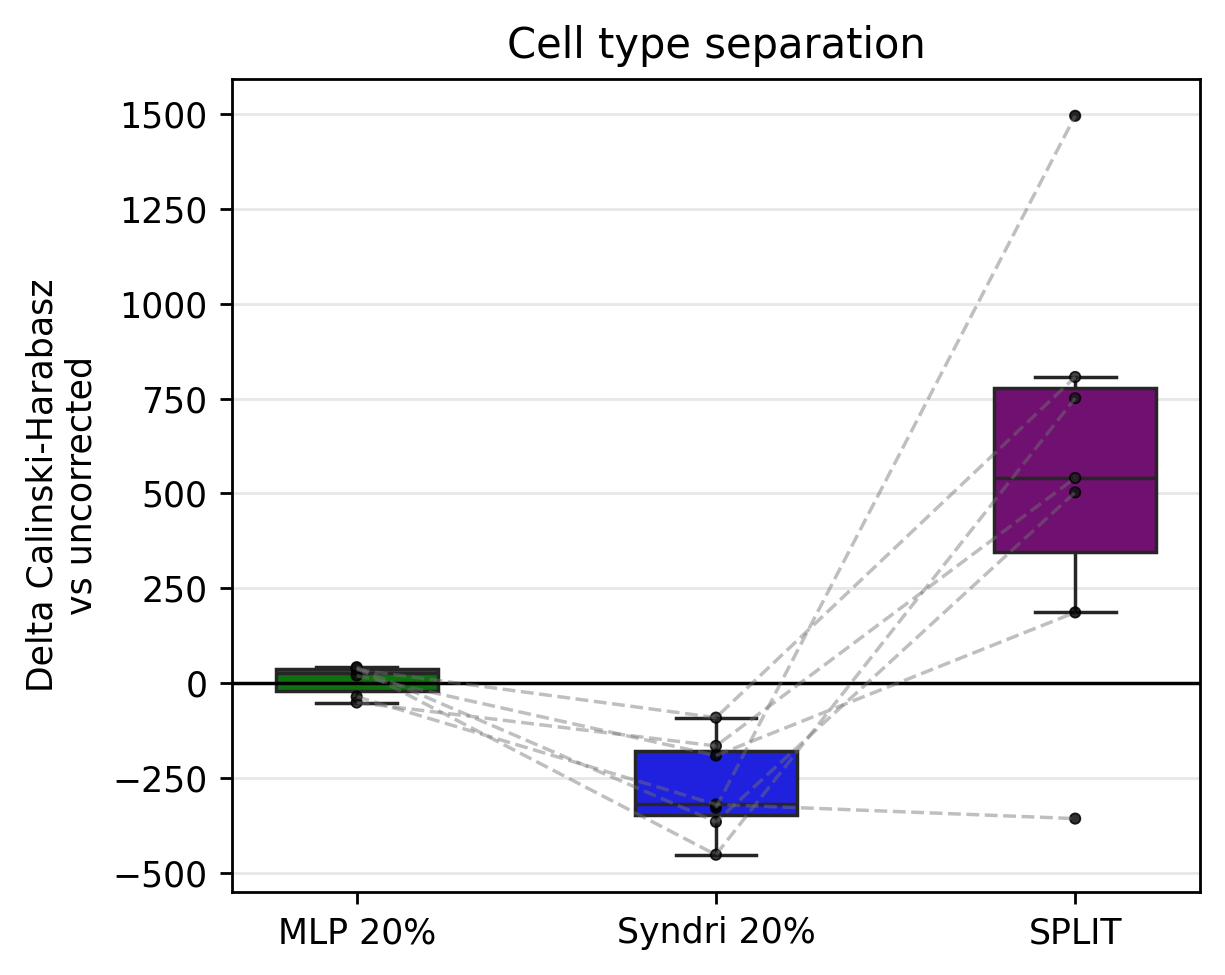

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from adjustText import adjust_text

baseline_case = "uncorrected"
method_cases = [
    # "cleaned_admixed_removed_frac_0.01",
    # "cleaned_admixed_removed_frac_0.02",
    # "cleaned_admixed_removed_frac_0.05",
    # "syndri_uncorrected",
    # "mlp_cleaned_removed_frac_0.01",
    # "syndri_cleaned_removed_frac_0.01",
    # "mlp_cleaned_removed_frac_0.1",
    # "syndri_cleaned_removed_frac_0.1",
    "mlp_cleaned_removed_frac_0.2",
    "syndri_cleaned_removed_frac_0.2",
    "split",
]

case_labels = {
    "cleaned_admixed_removed_frac_0.01": "Syndri 1%" ,
    "cleaned_admixed_removed_frac_0.02": "Syndri 2%",
    "cleaned_admixed_removed_frac_0.05": "Syndri 5%",
    "uncorrected": "Uncorrected",
    "mlp_cleaned_removed_frac_0.01": "MLP 1%",
    "syndri_cleaned_removed_frac_0.01": "Syndri 1%",
    "mlp_cleaned_removed_frac_0.1": "MLP 10%",
    "syndri_cleaned_removed_frac_0.1": "Syndri 10%",
    "mlp_cleaned_removed_frac_0.2": "MLP 20%",
    "syndri_cleaned_removed_frac_0.2": "Syndri 20%",
    "split": "SPLIT",
}

metrics = [
    (
        "calinski_harabasz",
        "Cell type separation",
        "Delta Calinski-Harabasz\nvs uncorrected",
    ),
    # (
    #     "davies_bouldin",
    #     "Cluster compactness/separation",
    #     "Delta Davies-Bouldin\nvs uncorrected",
    # ),
    # (
    #     "leiden_adjusted_rand_vs_label",
    #     "Leiden ARI",
    #     "Delta Leiden ARI\nvs uncorrected",
    # ),
    # (
    #     "silhouette_score",
    #     "Silhouette (Cell Type)",
    #     "Delta silhouette score\nvs uncorrected",
    # ),
]

id_cols = ["tissue"]
# if "source_file" in sep_df.columns:
#     id_cols = ["source_file"]
# elif "filename" in sep_df.columns:
#     id_cols = ["filename"]

plot_base = sep_df[
    (sep_df["case"].isin([baseline_case] + method_cases))&
    (sep_df["dropout_fraction"]==0.0)
].copy()

plot_base["sample_id"] = plot_base[id_cols[0]].astype(str)
plot_base["tissue"] = plot_base["sample_id"].apply(
    lambda x: x.split("/")[-1].split(".")[0]
)
delta_frames = []

for metric, _, _ in metrics:
    print(plot_base)
    wide = (
        plot_base
        .pivot_table(
            index=["dropout","sample_id", "tissue"],
            columns="case",
            values=metric,
            aggfunc="mean",
        )
        .reset_index()
    )
    for case in method_cases:
        required_cols = [
            "dropout",
            "sample_id",
            "tissue",
            baseline_case,
            case,
        ]
        print(wide)
        # Skip a method if it is entirely absent from the current data.
        if case not in wide.columns or baseline_case not in wide.columns:
            continue
        
        tmp = wide[required_cols].copy()
        tmp["case"] = case
        tmp["case_label"] = case_labels[case]
        tmp["metric"] = metric
        tmp["delta"] = tmp[case] - tmp[baseline_case]

        delta_frames.append(
            tmp[
                [
                    "dropout",
                    "sample_id",
                    "tissue",
                    "case",
                    "case_label",
                    "metric",
                    "delta",
                ]
            ]
        )

delta_df = pd.concat(delta_frames, ignore_index=True)

delta_df["case_label"] = pd.Categorical(
    delta_df["case_label"],
    categories=[case_labels[c] for c in method_cases],
    ordered=True,
)

palette = {
    "Syndri 20%": sns.color_palette("Blues", n_colors=4)[-1],
    "SPLIT": "purple",
}

palette = dict(
    zip(
        [case_labels[c] for c in method_cases],
        # sns.color_palette(
        #     "Blues",
        #     n_colors=len(method_cases[:-1]),
        ["green","blue","purple"],
    )
)


def plot_metric_delta(ax, data, metric, title, ylabel):
    sub = data[data["metric"] == metric].copy()
    sub = sub.dropna(subset=["delta"])
    # print(sub.head())
    sns.boxplot(    
        data=sub,
        x="case_label",
        y="delta",
        order=[case_labels[c] for c in method_cases],
        palette=palette,
        width=0.45,
        showfliers=False,
        ax=ax,
    )

    sns.stripplot(
        data=sub,
        x="case_label",
        y="delta",
        order=[case_labels[c] for c in method_cases],
        hue="tissue",
        dodge=False,
        jitter=0,
        size=3,
        linewidth=0.5,
        edgecolor="black",
        alpha=0.85,
        ax=ax,
        legend=False,
        color="black",
    )

    x_lookup = {
        label: i
        for i, label in enumerate(
            [case_labels[c] for c in method_cases]
        )
    }

    label_offsets = {
        "Syndri 20%": -0.08,
        "SPLIT": 0.08,
    }

    texts = []

    for _, row in sub.iterrows():
        # print(row["tissue"])

        x = (
            x_lookup[row["case_label"]]
            + label_offsets.get(row["case_label"], 0.0)
        )
        y = row["delta"]

        # if row["tissue"].split('_')[3] == 'B1':
        # print(row['tissue'])
        texts.append(
            ax.text(
                x,
                y,
                "_".join(row["tissue"].split("_")[4:-4]),
                # row['tissue'],
                fontsize=4,
                ha="center",
                va="bottom",
                alpha=0.8,
            )
        )
        # print("_".join(row["tissue"].split("_")[4:-7]))

    # adjust_text(texts,arrowprops=dict(arrowstyle="->", color='red', lw=0.5))

    paired = (
        sub
        .pivot_table(
            index=["dropout","sample_id", "tissue"],
            columns="case_label",
            values="delta",
            aggfunc="mean",
            observed=False,
        )
        .reset_index()
    )

    method_labels = [case_labels[c] for c in method_cases]

    for _, sample in paired.iterrows():
        available_labels = [
            label
            for label in method_labels
            if label in paired.columns and pd.notna(sample[label])
        ]

        if len(available_labels) >= 2:
            xs = [x_lookup[label] for label in available_labels]
            ys = [sample[label] for label in available_labels]

            ax.plot(
                xs,
                ys,
                color="0.45",
                alpha=0.45,
                linewidth=1,
                zorder=5,
                linestyle="--",
            )

    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.grid(True, axis="y", alpha=0.3)

delta_df['eval_config'] = delta_df['dropout']
eval_configs = delta_df["eval_config"].dropna().unique()

for eval_config in eval_configs:
    config_df = delta_df[
        delta_df["eval_config"] == eval_config
    ].copy()

    fig, axes_grid = plt.subplots(
        1,
        1,
        figsize=(5, 4),
        sharex=True,
        dpi=250,
    )
    axes = [axes_grid]

    for ax, (metric, title, ylabel) in zip(axes, metrics):
        plot_metric_delta(
            ax=ax,
            data=config_df,
            metric=metric,
            title=title,
            ylabel=ylabel,
        )

    # fig.suptitle(
    #     f"Evaluation configuration: {eval_config}",
    #     fontsize=12,
    #     y=1.02,
    # )

    plt.tight_layout()
    plt.show()

/tmp/ipykernel_1539307/1022569616.py:126: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


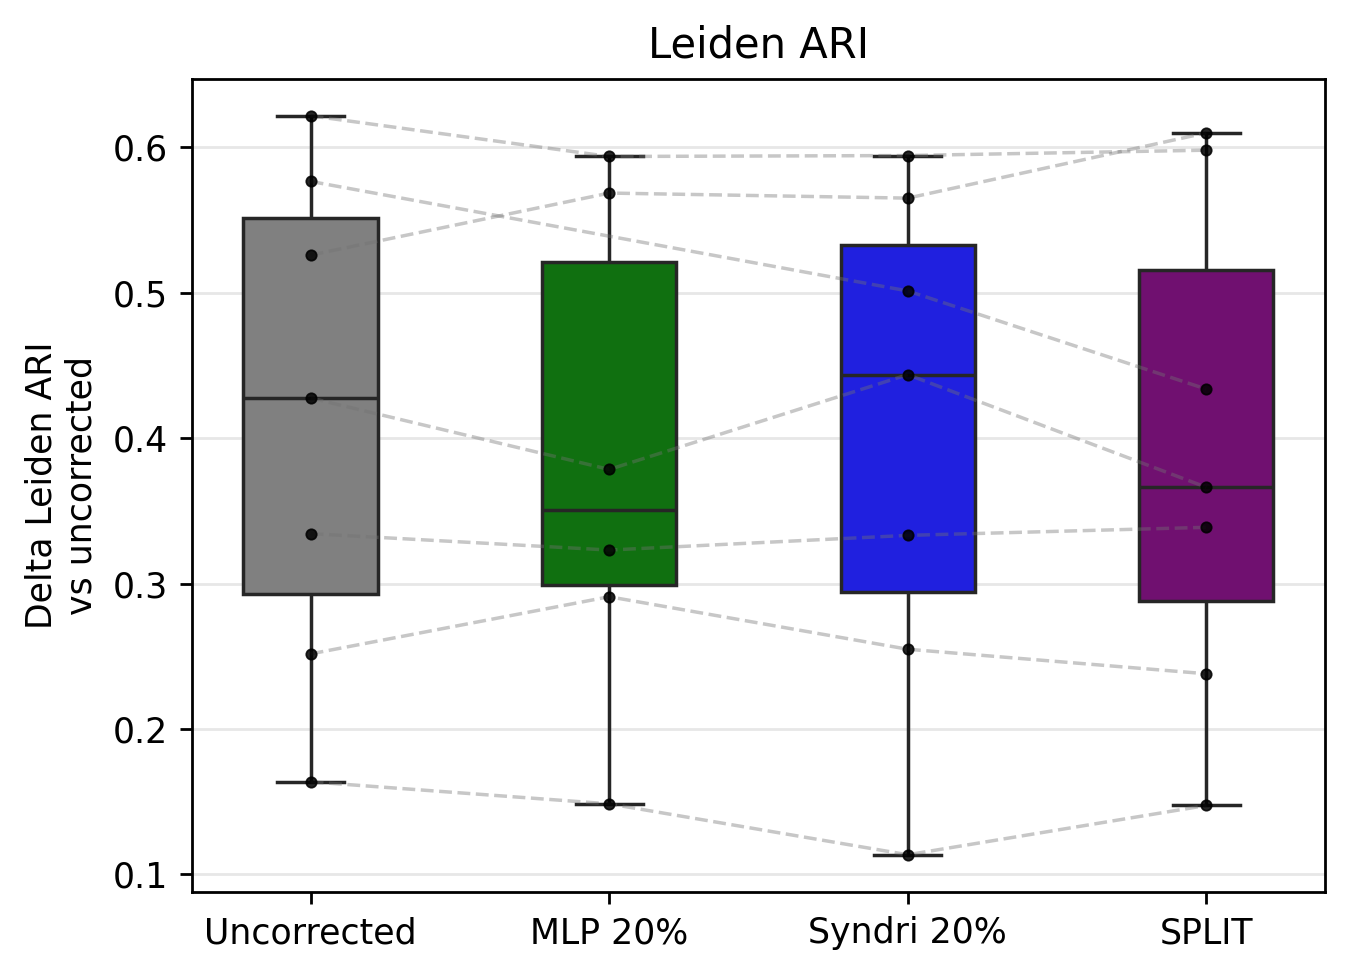

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

baseline_case = "uncorrected"

method_cases = [
    "mlp_cleaned_removed_frac_0.2",
    "syndri_cleaned_removed_frac_0.2",
    "split",
]

# Include the baseline when plotting actual values
plot_cases = [baseline_case] + method_cases

case_labels = {
    "uncorrected": "Uncorrected",
    "mlp_cleaned_removed_frac_0.1": "MLP 10%",
    "syndri_cleaned_removed_frac_0.1": "Syndri 10%",
    "mlp_cleaned_removed_frac_0.2": "MLP 20%",
    "syndri_cleaned_removed_frac_0.2": "Syndri 20%",
    "split": "SPLIT",
}

metrics = [
    # (
    #     "calinski_harabasz",
    #     "Cell type separation",
    #     "Calinski–Harabasz score",
    # ),
    # (
    #     "davies_bouldin",
    #     "Cluster compactness/separation",
    #     "Delta Davies-Bouldin\nvs uncorrected",
    # ),
    (
        "leiden_adjusted_rand_vs_label",
        "Leiden ARI",
        "Delta Leiden ARI\nvs uncorrected",
    ),
    # (
    #     "silhouette_score",
    #     "Silhouette (Cell Type)",
    #     "Delta silhouette score\nvs uncorrected",
    # ),
]

id_col = "tissue"

plot_base = sep_df.loc[
    sep_df["case"].isin(plot_cases)
    & sep_df["dropout_fraction"].eq(0.00)
].copy()

plot_base["sample_id"] = plot_base[id_col].astype(str)

plot_base["tissue"] = (
    plot_base["sample_id"]
    .str.split("/")
    .str[-1]
    .str.split(".")
    .str[0]
)

# Average repeated measurements/trials for each tissue, dropout, case,
# and metric before plotting.
value_frames = []

for metric, _, _ in metrics:
    tmp = (
        plot_base
        .groupby(
            [
                "dropout",
                "sample_id",
                "tissue",
                "case",
            ],
            observed=True,
            as_index=False,
        )[metric]
        .mean()
        .rename(columns={metric: "value"})
    )

    tmp["metric"] = metric
    tmp["case_label"] = tmp["case"].map(case_labels)

    value_frames.append(tmp)

value_df = pd.concat(
    value_frames,
    ignore_index=True,
)

method_order = [
    case_labels[case]
    for case in plot_cases
]

value_df["case_label"] = pd.Categorical(
    value_df["case_label"],
    categories=method_order,
    ordered=True,
)

palette = {
    "Uncorrected": "gray",
    "MLP 20%": "green",
    "Syndri 20%": "blue",
    "SPLIT": "purple",
}

def plot_metric_values(
    ax,
    data,
    metric,
    title,
    ylabel,
):
    sub = data.loc[
        data["metric"].eq(metric)
    ].dropna(subset=["value"]).copy()

    sns.boxplot(
        data=sub,
        x="case_label",
        y="value",
        order=method_order,
        palette=palette,
        width=0.45,
        showfliers=False,
        ax=ax,
    )

    sns.stripplot(
        data=sub,
        x="case_label",
        y="value",
        order=method_order,
        jitter=0,
        size=3,
        linewidth=0.5,
        edgecolor="black",
        alpha=0.85,
        color="black",
        legend=False,
        ax=ax,
        zorder=6,
    )

    x_lookup = {
        label: index
        for index, label in enumerate(method_order)
    }

    label_offsets = {
        "Uncorrected": -0.06,
        "MLP 20%": -0.03,
        "Syndri 20%": 0.03,
        "SPLIT": 0.06,
    }

    # Add tissue labels beside points
    for _, row in sub.iterrows():
        tissue_label = "_".join(
            row["tissue"].split("_")[4:-4]
        )

        # Fall back to the complete tissue name if slicing is empty
        if not tissue_label:
            tissue_label = row["tissue"]
        if tissue_label.startswith('B1_'):
            ax.text(
                x_lookup[row["case_label"]]
                + label_offsets.get(row["case_label"], 0),
                row["value"],
                tissue_label,
                fontsize=4,
                ha="center",
                va="bottom",
                alpha=0.8,
                zorder=7,
            )

    # Convert to wide form so each tissue can be connected
    paired = (
        sub
        .pivot_table(
            index=[
                "dropout",
                "sample_id",
                "tissue",
            ],
            columns="case_label",
            values="value",
            aggfunc="mean",
            observed=False,
        )
        .reset_index()
    )

    for _, sample_row in paired.iterrows():
        available_labels = [
            label
            for label in method_order
            if (
                label in paired.columns
                and pd.notna(sample_row[label])
            )
        ]

        if len(available_labels) >= 2:
            xs = [
                x_lookup[label]
                for label in available_labels
            ]

            ys = [
                sample_row[label]
                for label in available_labels
            ]

            ax.plot(
                xs,
                ys,
                color="0.45",
                alpha=0.4,
                linewidth=1,
                linestyle="--",
                zorder=4,
            )

    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.grid(
        True,
        axis="y",
        alpha=0.3,
    )

value_df["eval_config"] = value_df["dropout"]

eval_configs = (
    value_df["eval_config"]
    .dropna()
    .sort_values()
    .unique()
)

for eval_config in eval_configs:
    config_df = value_df.loc[
        value_df["eval_config"].eq(eval_config)
    ].copy()

    fig, ax = plt.subplots(
        figsize=(5.5, 4),
        dpi=250,
    )

    metric, title, ylabel = metrics[0]

    plot_metric_values(
        ax=ax,
        data=config_df,
        metric=metric,
        title=title,
        ylabel=ylabel,
    )

    # Optional:
    # ax.set_title(
    #     f"{title}\nDropout: {eval_config}"
    # )

    plt.tight_layout()
    plt.show()

In [15]:
sep_df['case'].unique()

array(['syndri_uncorrected', 'syndri_cleaned_removed_frac_0.01',
       'syndri_cleaned_removed_frac_0.02',
       'syndri_cleaned_removed_frac_0.05',
       'syndri_cleaned_removed_frac_0.1',
       'syndri_cleaned_removed_frac_0.2', 'mlp_uncorrected',
       'mlp_cleaned_removed_frac_0.01', 'mlp_cleaned_removed_frac_0.02',
       'mlp_cleaned_removed_frac_0.05', 'mlp_cleaned_removed_frac_0.1',
       'mlp_cleaned_removed_frac_0.2', 'split'], dtype=object)